# RQ1 – Lending Landscape (Pandas)

**Question:** What is the 2024 distribution of application outcomes (including the baseline denial rate), loan amounts and income, and the mix of loan types and purposes?

- **Data:** S0 (all records) from `clean_pandas/S0_all`; denial rates use S1 (originated + denied).
- **Outputs:** `rq1_pandas/` (CSV tables, PNG figures)
- The last section compares the results with the PySpark version in `rq1_spark/`; run it after `RQ1_Spark.ipynb`.

## Setup and Data Loading

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/clean
!cp -rn /content/drive/MyDrive/hmda/clean_pandas/S0_all /content/clean/

import os, sys, time
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/hmda/"
OUT  = BASE + "rq1_pandas/"
os.makedirs(OUT, exist_ok=True)
sys.path.insert(0, BASE)
import rules

COLS = ["action_taken", "loan_amount", "income", "loan_type", "loan_purpose",
        "lien_status", "denied_flag", "log_income", "log_loan_amount"]

t0 = time.time()
s0 = (ds.dataset("/content/clean/S0_all", format="parquet", partitioning="hive")
        .to_table(columns=COLS).to_pandas(strings_to_categorical=True))
print(f"Load S0: {time.time()-t0:.1f}s | {len(s0):,} rows | "
      f"RAM {s0.memory_usage(deep=True).sum()/1e9:.2f} GB")

# HMDA code labels
ACTION = {"1": "Originated", "2": "Approved not accepted", "3": "Denied",
          "4": "Withdrawn", "5": "Incomplete", "6": "Purchased",
          "7": "Preapproval denied", "8": "Preapproval approved not accepted"}
LOAN_TYPE = {"1": "Conventional", "2": "FHA", "3": "VA", "4": "USDA (RHS/FSA)"}
PURPOSE = {"1": "Home purchase", "2": "Home improvement", "31": "Refinancing",
           "32": "Cash-out refinancing", "4": "Other purpose", "5": "Not applicable"}

s0["action_label"]  = s0["action_taken"].astype(str).map(ACTION).astype("category")
s0["type_label"]    = s0["loan_type"].astype(str).map(LOAN_TYPE).astype("category")
s0["purpose_label"] = s0["loan_purpose"].astype(str).map(PURPOSE).astype("category")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
Load S0: 5.9s | 12,259,199 rows | RAM 0.45 GB


## RQ1.1 — Application Outcomes

,outcome,count,share_%
0,Originated,6197085,50.55
1,Denied,2103462,17.16
2,Withdrawn,1538273,12.55
3,Purchased,1276504,10.41
4,Incomplete,581940,4.75
5,Approved not accepted,361232,2.95
6,Preapproval approved not accepted,153391,1.25
7,Preapproval denied,47312,0.39


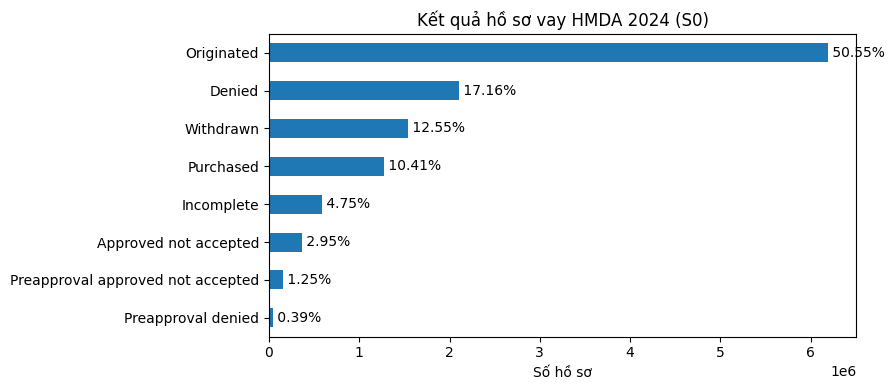

In [ ]:
total = len(s0)
outcome = (s0["action_label"].value_counts().rename_axis("outcome")
             .reset_index(name="count"))
outcome["share_%"] = (outcome["count"] / total * 100).round(2)
outcome.to_csv(OUT + "R1_outcomes.csv", index=False)
display(outcome)

ax = outcome.sort_values("count").plot.barh(x="outcome", y="count", legend=False, figsize=(9, 4))
ax.set_xlabel("Applications"); ax.set_ylabel("")
ax.set_title("Application Outcomes, HMDA 2024 (S0)")
for i, (c, s) in enumerate(zip(outcome.sort_values("count")["count"],
                               outcome.sort_values("count")["share_%"])):
    ax.text(c, i, f" {s}%", va="center")
plt.tight_layout(); plt.savefig(OUT + "R1_outcomes.png", dpi=150); plt.show()

## RQ1.2 — Baseline Denial Rate by Loan Type and Loan Purpose

Baseline denial rate = denied / (originated + denied) = 25.34%

=== Theo loan type ===


,applications,denial_rate,share_of_S1_%
type_label,,,
Conventional,6601706,26.71,79.53
FHA,1072243,22.42,12.92
VA,584996,16.10,7.05
USDA (RHS/FSA),41602,12.71,0.50



=== Theo loan purpose ===


,applications,denial_rate,share_of_S1_%
purpose_label,,,
Home purchase,4158055,15.01,50.09
Cash-out refinancing,1165962,33.99,14.05
Other purpose,1078317,44.41,12.99
Home improvement,972499,39.11,11.72
Refinancing,922327,24.20,11.11
Not applicable,3387,26.16,0.04


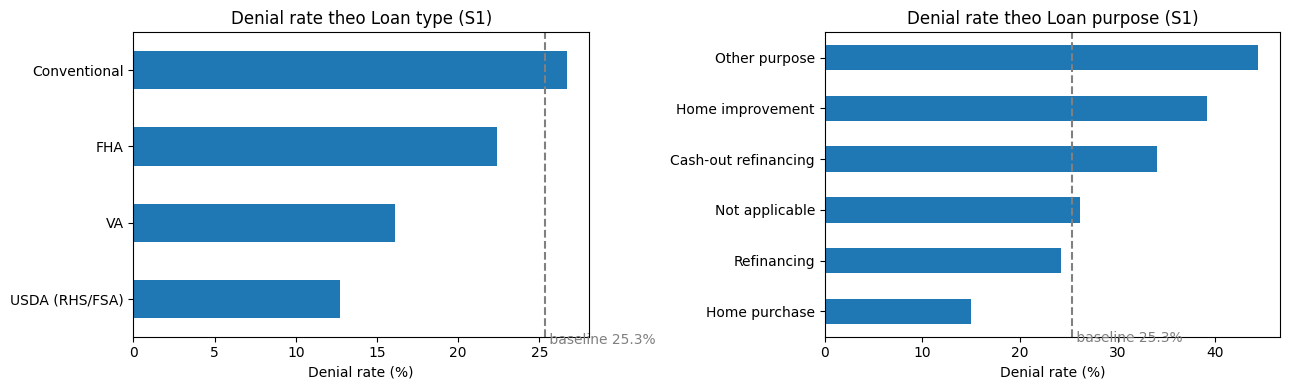

In [ ]:
s1 = s0[s0["action_taken"].isin(rules.S1_CODES)]
base_rate = s1["denied_flag"].mean() * 100
print(f"Baseline denial rate = denied / (originated + denied) = {base_rate:.2f}%")

def rate_by(col):
    t = (s1.groupby(col, observed=True)["denied_flag"]
           .agg(applications="size", denial_rate="mean"))
    t["denial_rate"] = (t["denial_rate"] * 100).round(2)
    t["share_of_S1_%"] = (t["applications"] / len(s1) * 100).round(2)
    return t.sort_values("applications", ascending=False)

rate_type = rate_by("type_label")
rate_purpose = rate_by("purpose_label")
rate_type.to_csv(OUT + "R2_denial_by_loan_type.csv")
rate_purpose.to_csv(OUT + "R2_denial_by_purpose.csv")

print("\n=== Theo loan type ==="); display(rate_type)
print("\n=== Theo loan purpose ==="); display(rate_purpose)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, t, title in [(axes[0], rate_type, "Loan type"), (axes[1], rate_purpose, "Loan purpose")]:
    t["denial_rate"].sort_values().plot.barh(ax=ax)
    ax.axvline(base_rate, ls="--", c="grey"); ax.text(base_rate, -0.6, f" baseline {base_rate:.1f}%", c="grey")
    ax.set_xlabel("Denial rate (%)"); ax.set_ylabel(""); ax.set_title(f"Denial rate theo {title} (S1)")
plt.tight_layout(); plt.savefig(OUT + "R2_denial_rates.png", dpi=150); plt.show()

## RQ1.3 — Loan Amount and Income Distributions

,variable,unit,n,p1,Q1,median,Q3,IQR,p99,mean
0,loan_amount,USD,12259199,15000.0,105000.0,225000.0,375000.0,270000.0,1445000.0,315308.7
1,income,USD thousands,10313511,20.0,69.0,105.0,166.0,97.0,843.0,326.1


,loan_amount,income
type_label,,
Conventional,185000.0,112.0
FHA,275000.0,85.0
USDA (RHS/FSA),175000.0,73.0
VA,335000.0,102.0


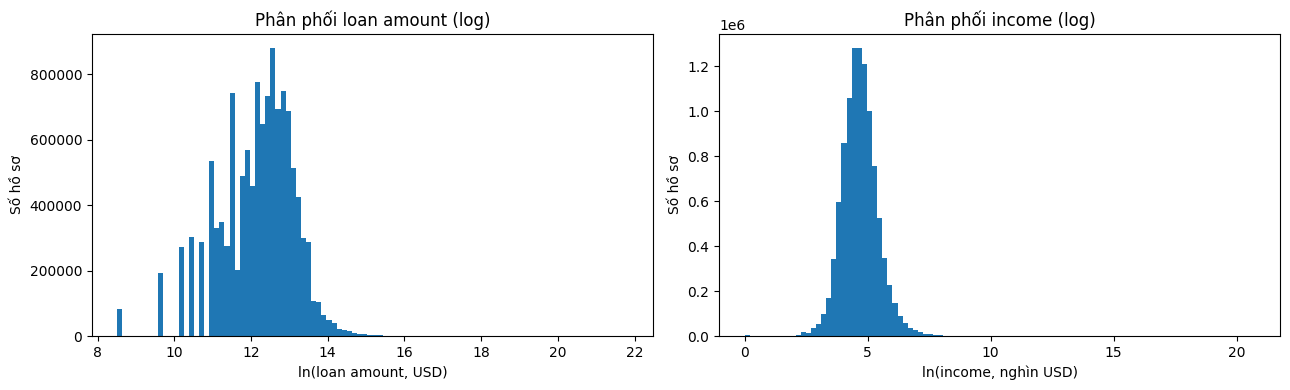

In [ ]:
def dist_stats(s, name, unit):
    q = s.quantile([0.01, 0.25, 0.5, 0.75, 0.99])
    return {"variable": name, "unit": unit, "n": int(s.notna().sum()),
            "p1": q[0.01], "Q1": q[0.25], "median": q[0.5], "Q3": q[0.75],
            "IQR": q[0.75] - q[0.25], "p99": q[0.99], "mean": s.mean()}

dist = pd.DataFrame([
    dist_stats(s0["loan_amount"], "loan_amount", "USD"),
    dist_stats(s0["income"], "income", "USD thousands"),
]).round(1)
dist.to_csv(OUT + "R3_distribution_stats.csv", index=False)
display(dist)

# Median by loan type
med_type = (s0.groupby("type_label", observed=True)[["loan_amount", "income"]]
              .median().round(0))
med_type.to_csv(OUT + "R3_median_by_loan_type.csv")
display(med_type)

# Histograms on log scale (full data)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(s0["log_loan_amount"].dropna(), bins=100)
axes[0].set_title("Loan amount distribution (log)"); axes[0].set_xlabel("ln(loan amount, USD)")
axes[1].hist(s0["log_income"].dropna(), bins=100)
axes[1].set_title("Income distribution (log)"); axes[1].set_xlabel("ln(income, USD thousands)")
for ax in axes: ax.set_ylabel("Applications")
plt.tight_layout(); plt.savefig(OUT + "R3_distributions_log.png", dpi=150); plt.show()

## RQ1.4 — Loan Type × Loan Purpose Mix

type_label,Conventional,FHA,USDA (RHS/FSA),VA,Total
purpose_label,,,,,
Cash-out refinancing,9.06,3.32,0.00,1.79,14.17
Home improvement,9.75,0.08,0.00,0.01,9.84
Home purchase,38.16,10.07,0.61,4.83,53.67
Not applicable,0.06,0.09,0.00,0.01,0.16
Other purpose,11.15,0.23,0.00,0.02,11.40
Refinancing,7.61,1.50,0.01,1.65,10.77
Total,75.79,15.29,0.62,8.31,100.01


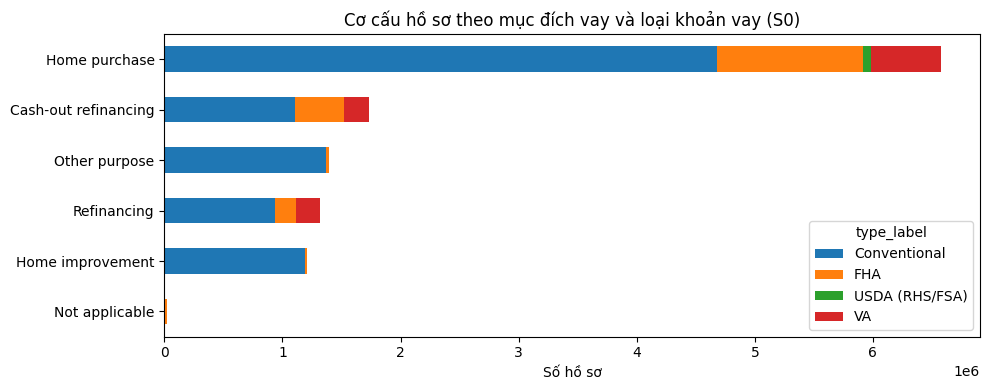

In [ ]:
mix = pd.crosstab(s0["purpose_label"], s0["type_label"], normalize="all") * 100
mix = mix.round(2)
mix["Total"] = mix.sum(axis=1)
mix.loc["Total"] = mix.sum()
mix.to_csv(OUT + "R4_mix_purpose_x_type.csv")
display(mix)

# Stacked bar chart: each loan purpose split by loan type
mix_plot = pd.crosstab(s0["purpose_label"], s0["type_label"])
ax = mix_plot.loc[mix_plot.sum(axis=1).sort_values().index].plot.barh(
        stacked=True, figsize=(10, 4))
ax.set_xlabel("Applications"); ax.set_ylabel("")
ax.set_title("Applications by Loan Purpose and Loan Type (S0)")
plt.tight_layout(); plt.savefig(OUT + "R4_mix.png", dpi=150); plt.show()

## Summary

In [ ]:
print(f"Total applications (S0): {total:,}")
print(f"Baseline denial rate (S1): {base_rate:.2f}%")
print("\nTop 3 application outcomes:")
print(outcome.head(3).to_string(index=False))
print(f"\nMedian loan amount: ${dist.loc[0,'median']:,.0f} | IQR: ${dist.loc[0,'IQR']:,.0f}")
print(f"Median income: ${dist.loc[1,'median']*1000:,.0f}/year | IQR: ${dist.loc[1,'IQR']*1000:,.0f}")
print("\nHighest denial rates by loan purpose:")
print(rate_purpose["denial_rate"].sort_values(ascending=False).head(3).to_string())
!ls -lh {OUT}

Total applications (S0): 12,259,199
Baseline denial rate (S1): 25.34%

Top 3 application outcomes:
   outcome   count  share_%
Originated 6197085    50.55
    Denied 2103462    17.16
 Withdrawn 1538273    12.55

Median loan amount: $225,000 | IQR: $270,000
Median income: $105,000/year | IQR: $97,000

Highest denial rates by loan purpose:
purpose_label
Other purpose           44.41
Home improvement        39.11
Cash-out refinancing    33.99
total 221K
-rw------- 1 root root 249 Nov 12 04:46 R1_outcomes.csv
-rw------- 1 root root 61K Nov 12 04:46 R1_outcomes.png
-rw------- 1 root root 158 Nov 12 04:46 R2_denial_by_loan_type.csv
-rw------- 1 root root 259 Nov 12 04:46 R2_denial_by_purpose.csv
-rw------- 1 root root 58K Nov 12 04:46 R2_denial_rates.png
-rw------- 1 root root 47K Nov 12 04:46 R3_distributions_log.png
-rw------- 1 root root 199 Nov 12 04:46 R3_distribution_stats.csv
-rw------- 1 root root 123 Nov 12 04:46 R3_median_by_loan_type.csv
-rw------- 1 root root 53K Nov 12 04:47 R4_